# Plot shareable raw acquisitions
This notebook plots downsampled accelerometer channels for all `.mat` files under `sample-data/raw/`.

It makes no network calls.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat

# Resolve the raw folder whether you run from repo root or from sample-data/.
raw_dir = Path('sample-data/raw')
if not raw_dir.exists():
    raw_dir = Path('raw')

paths = sorted(raw_dir.glob('*.mat'))
if not paths:
    raise FileNotFoundError(f'No .mat files found in: {raw_dir.resolve()}')

print(f'Found {len(paths)} raw acquisitions in {raw_dir}')

Found 11 raw acquisitions in raw


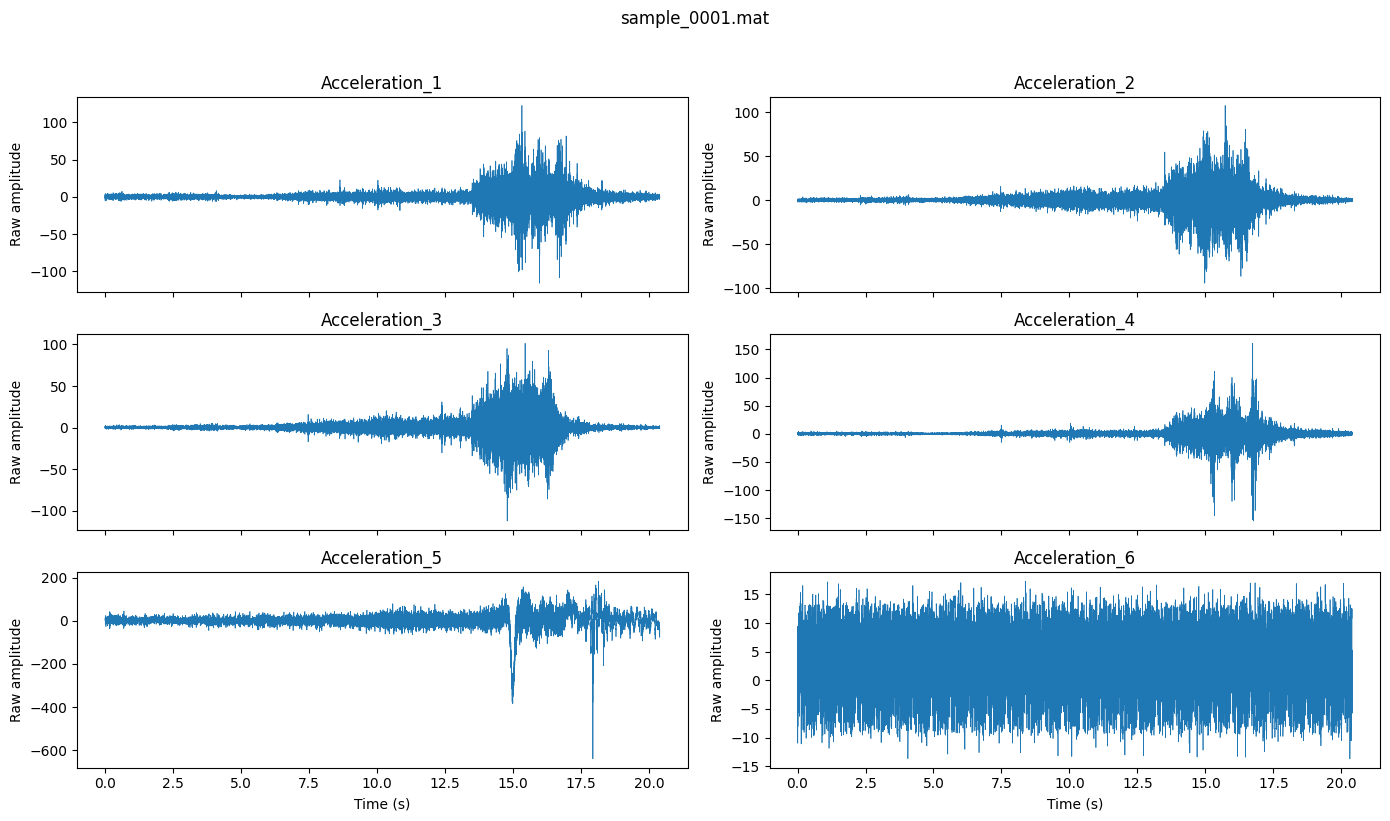

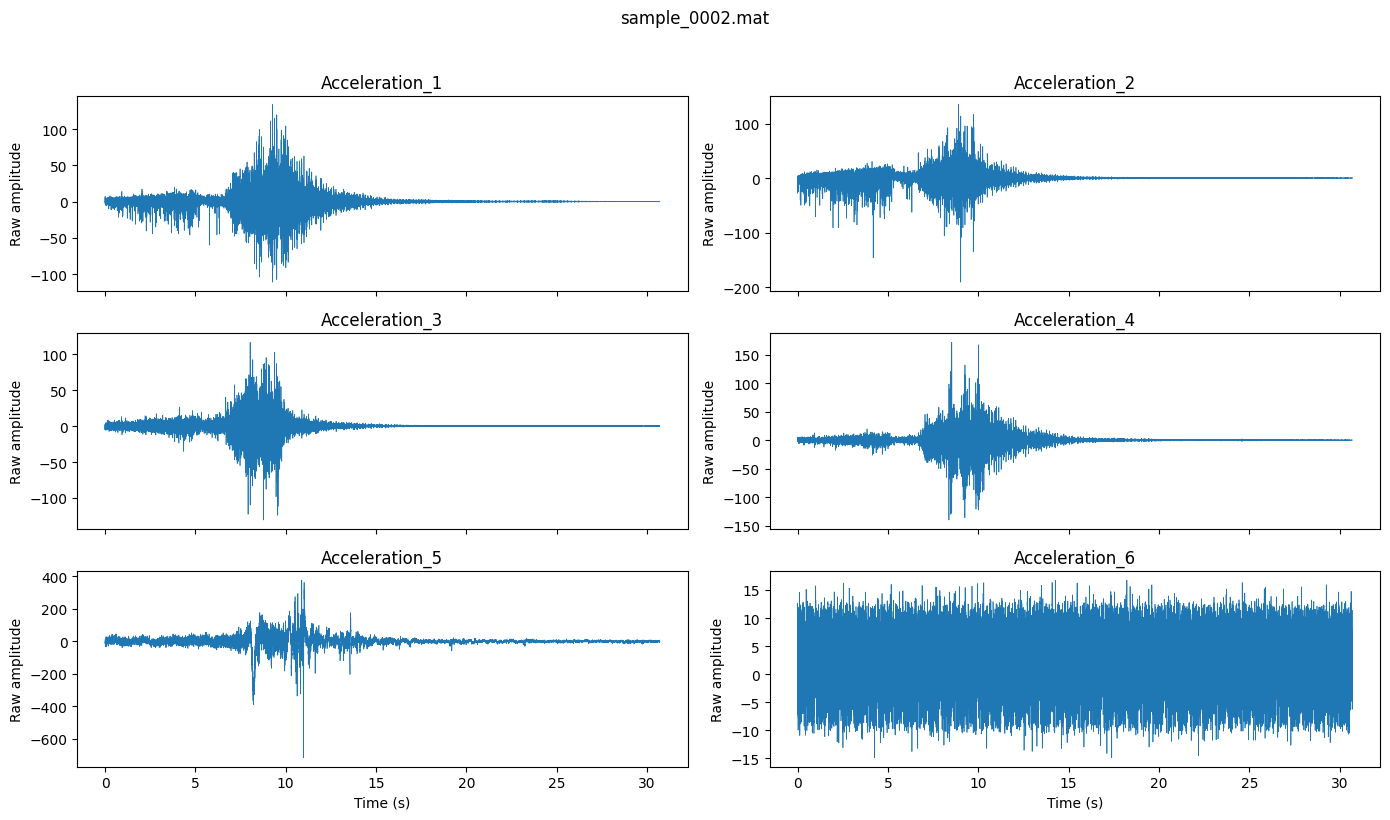

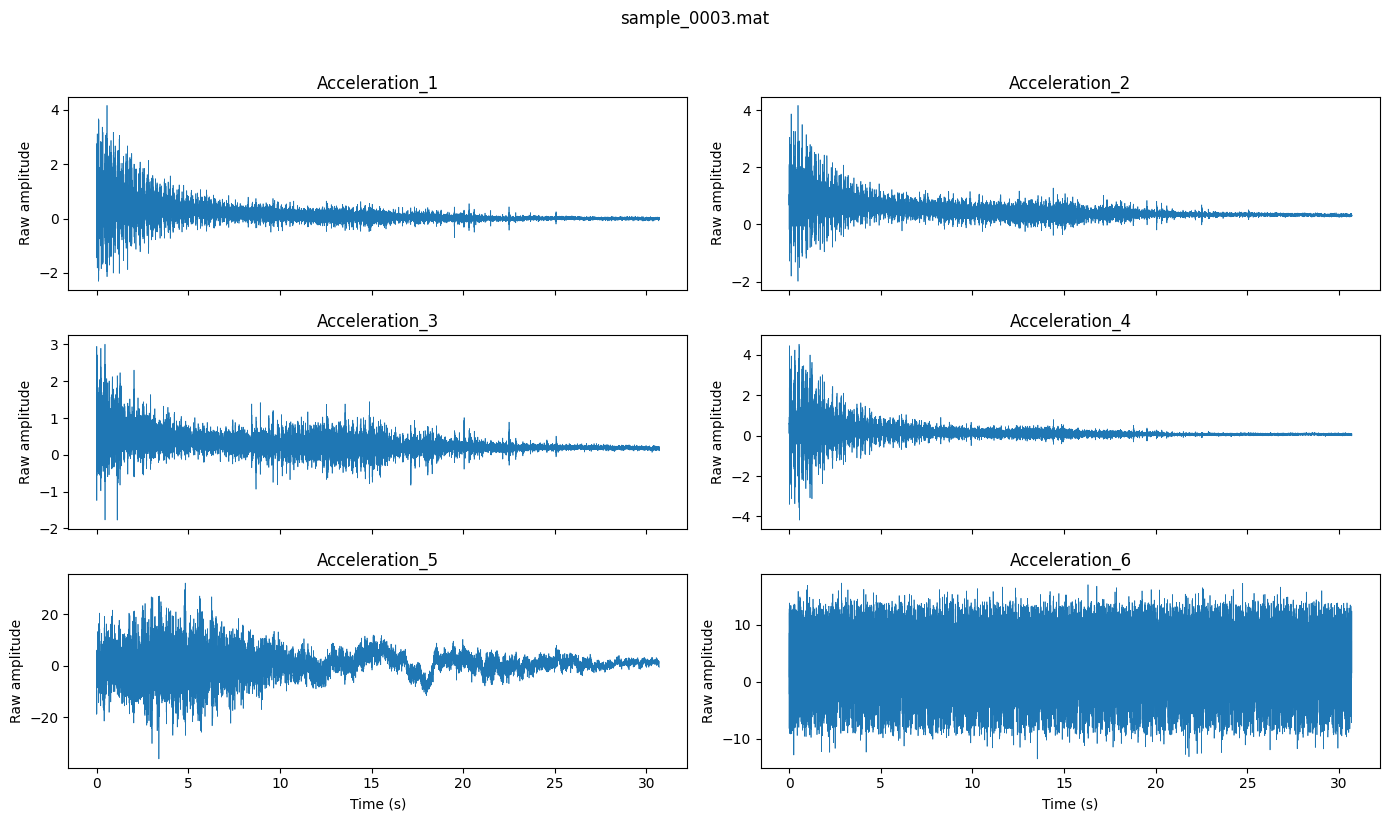

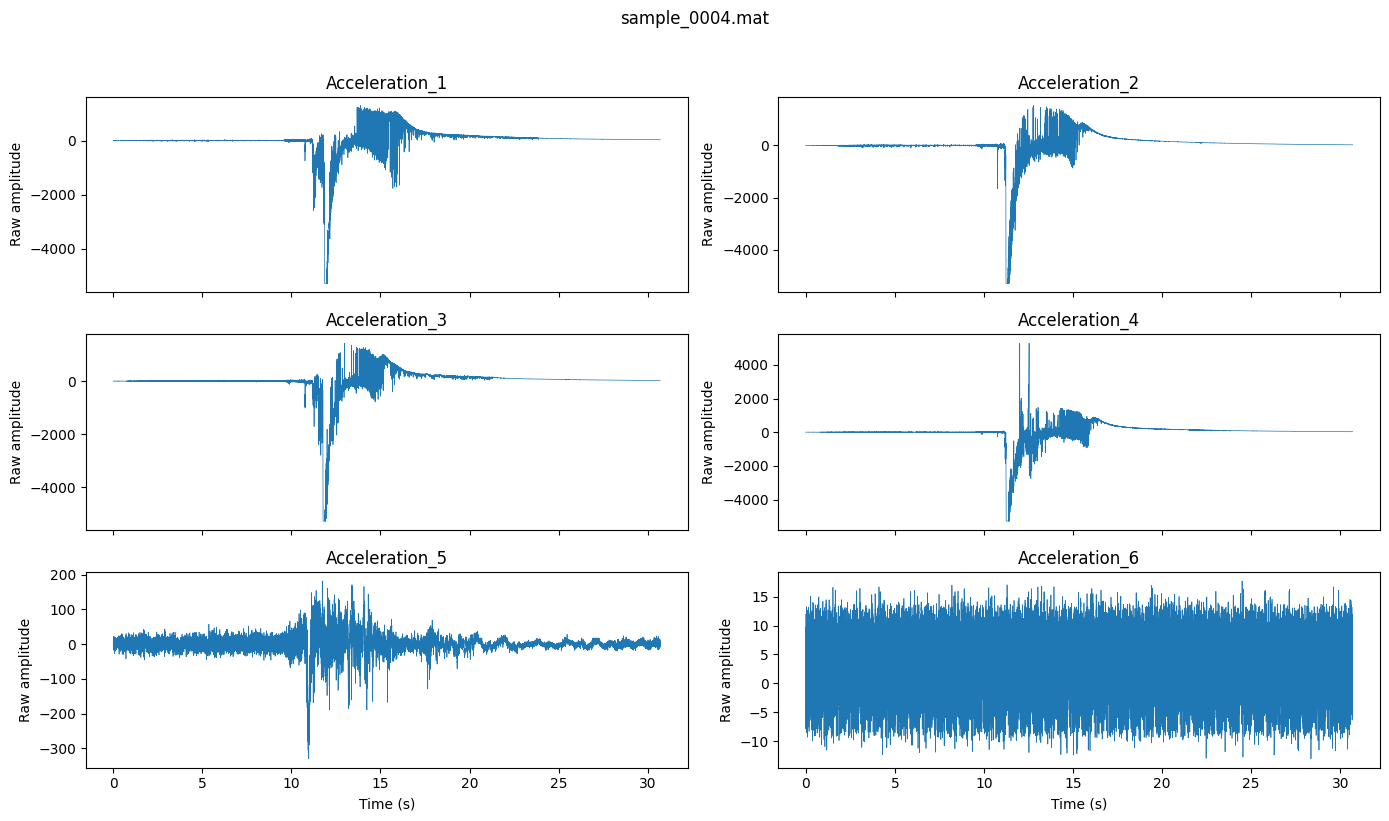

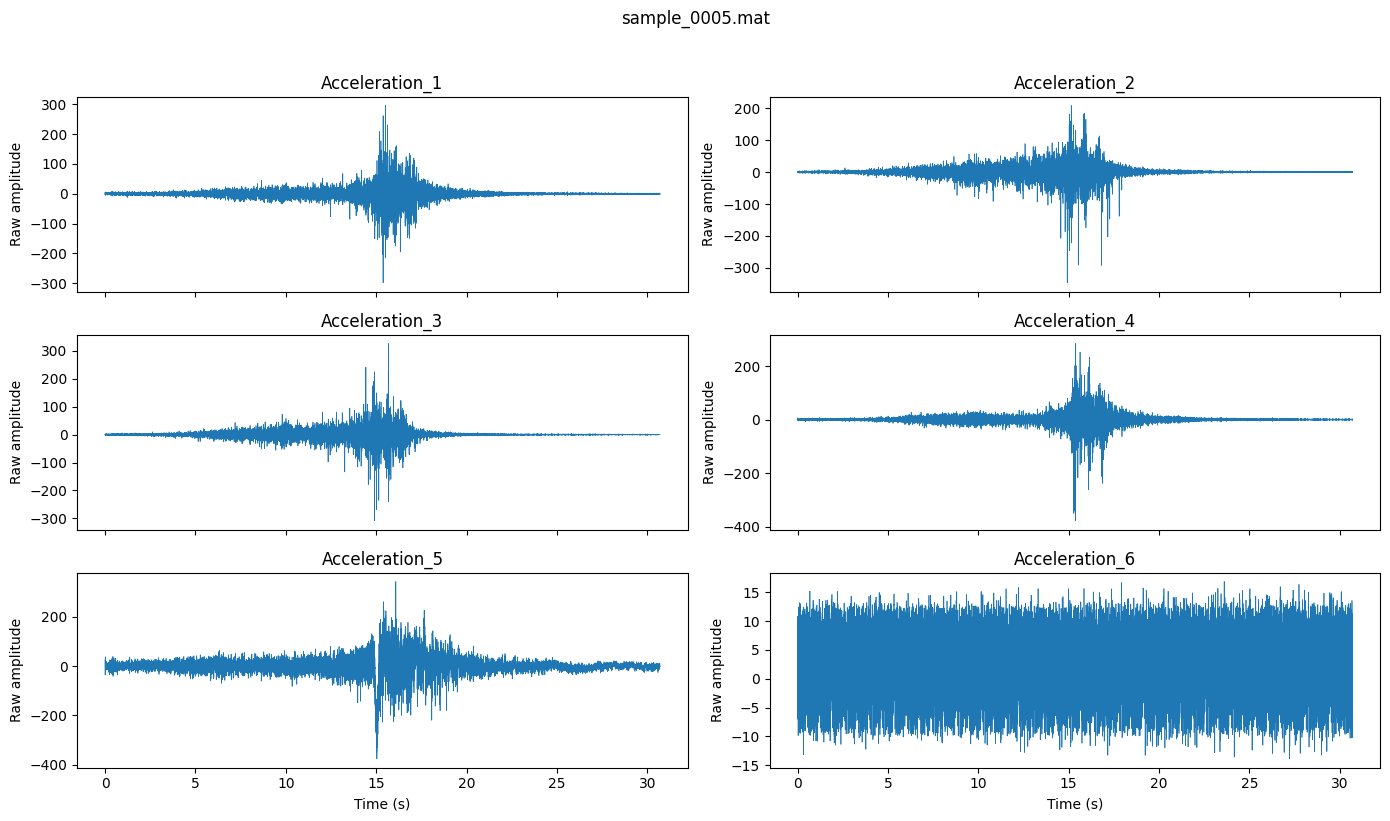

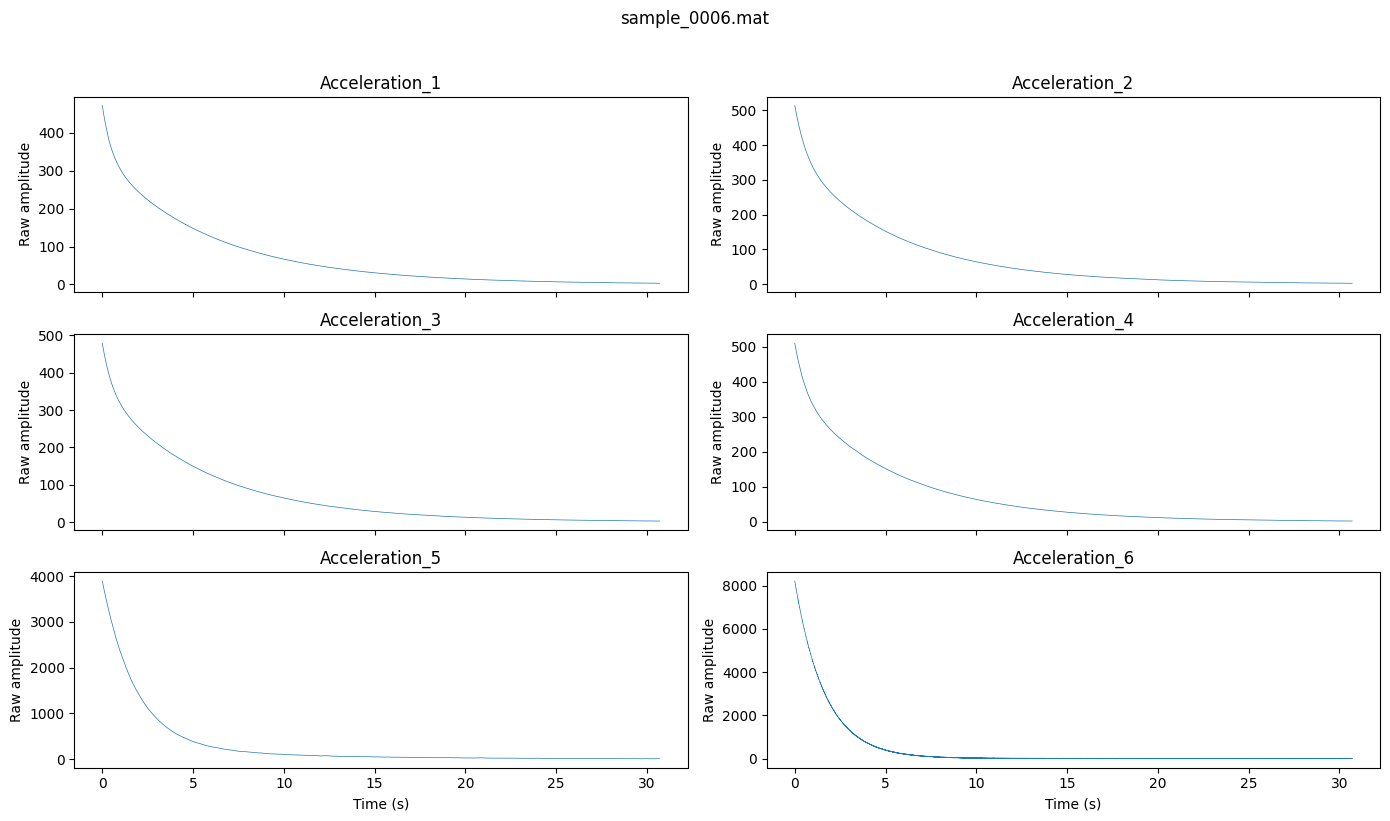

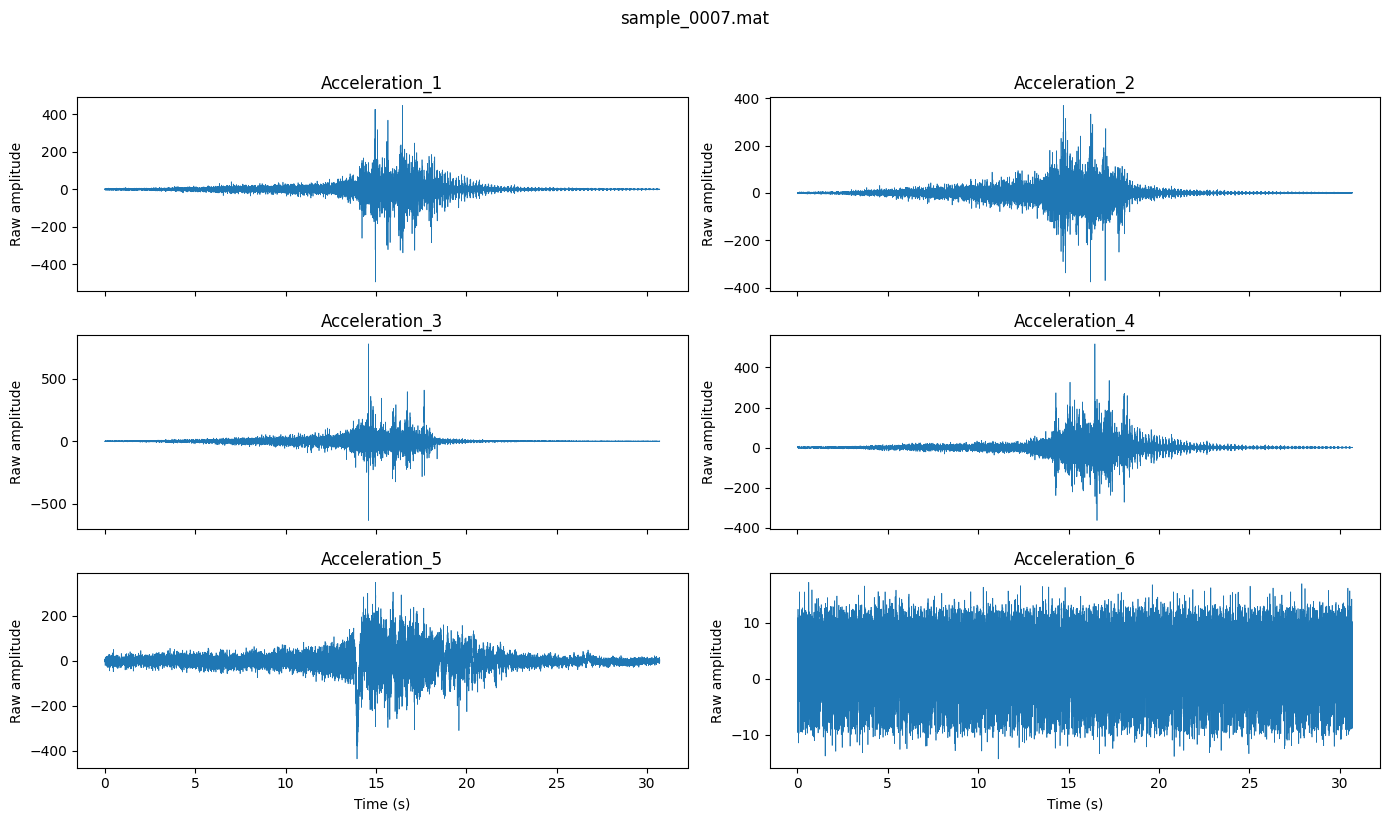

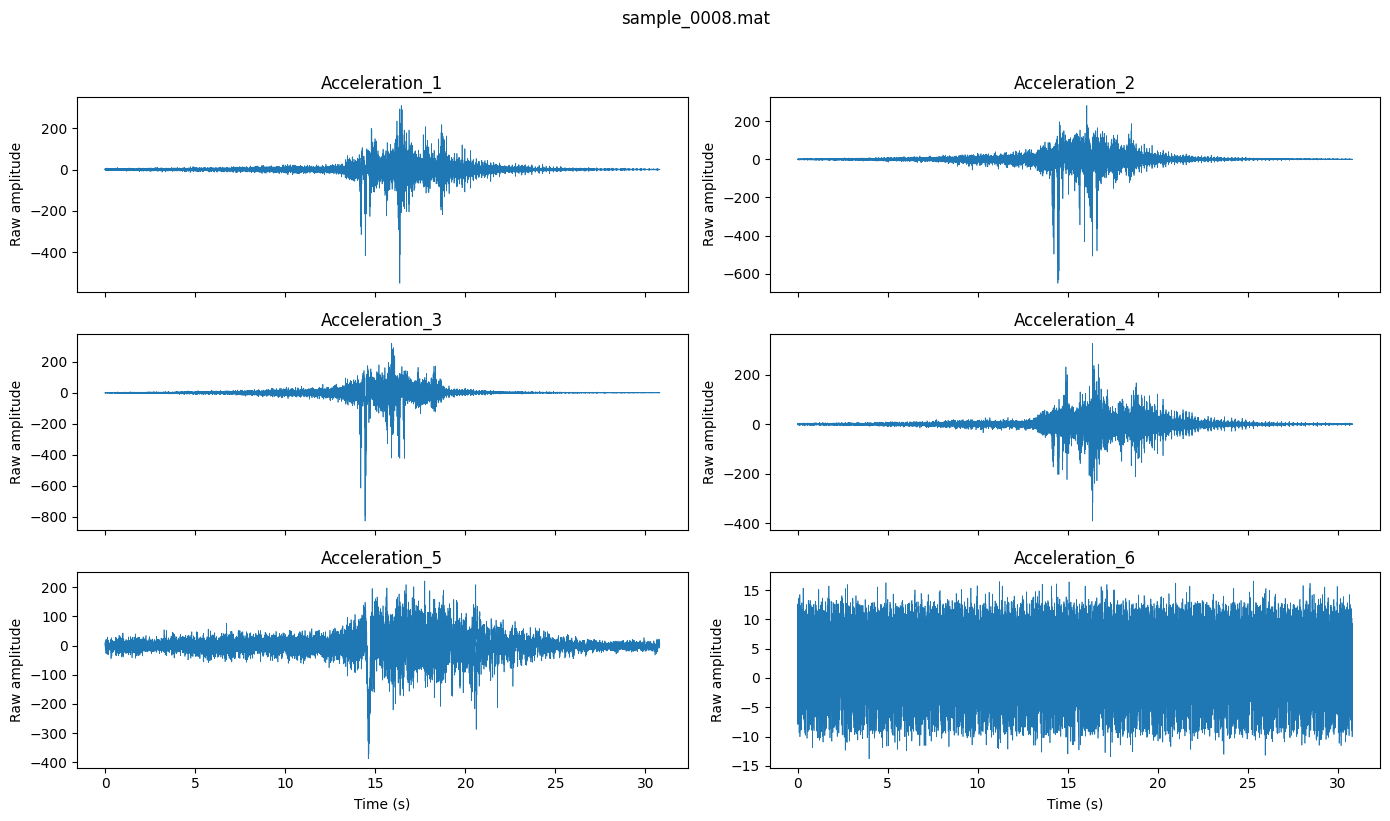

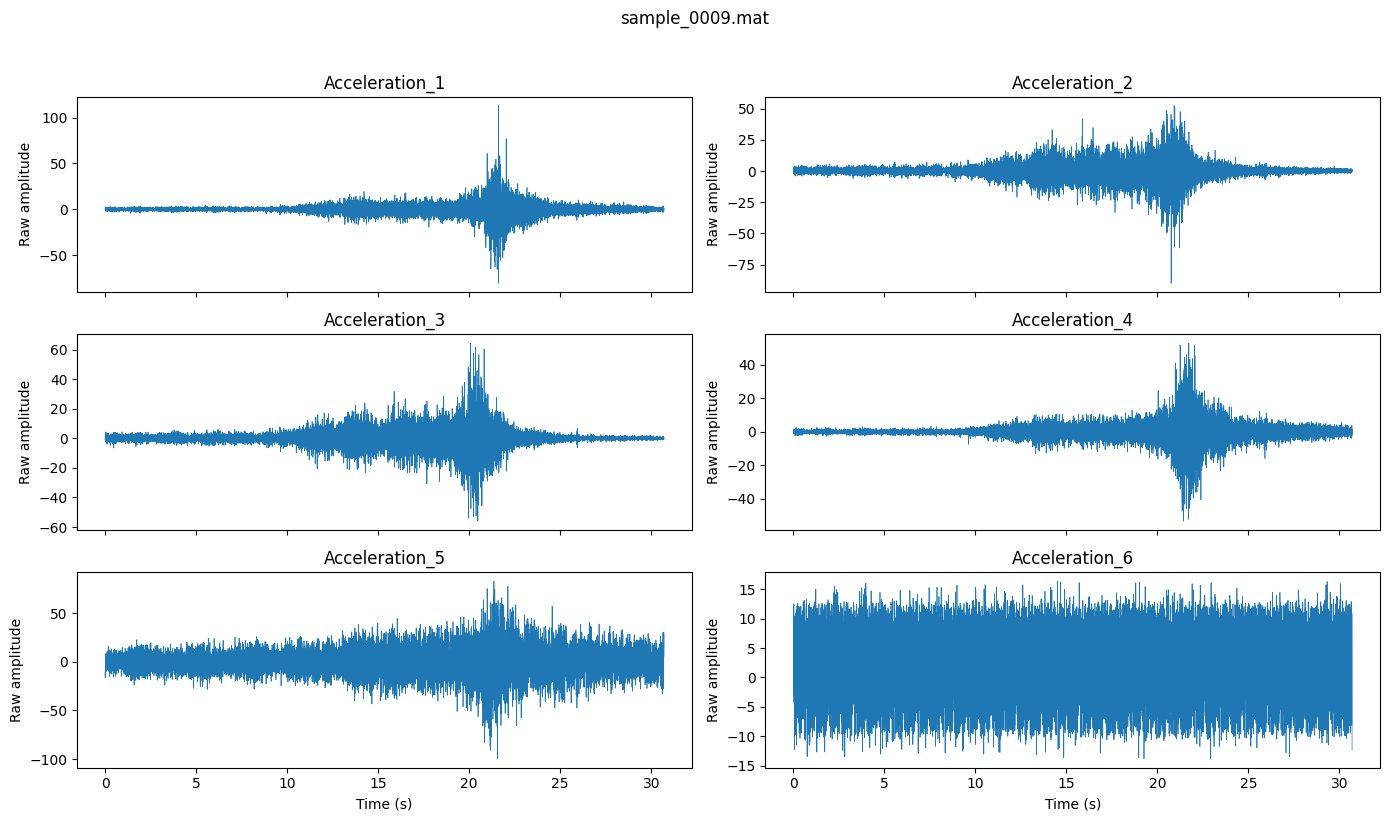

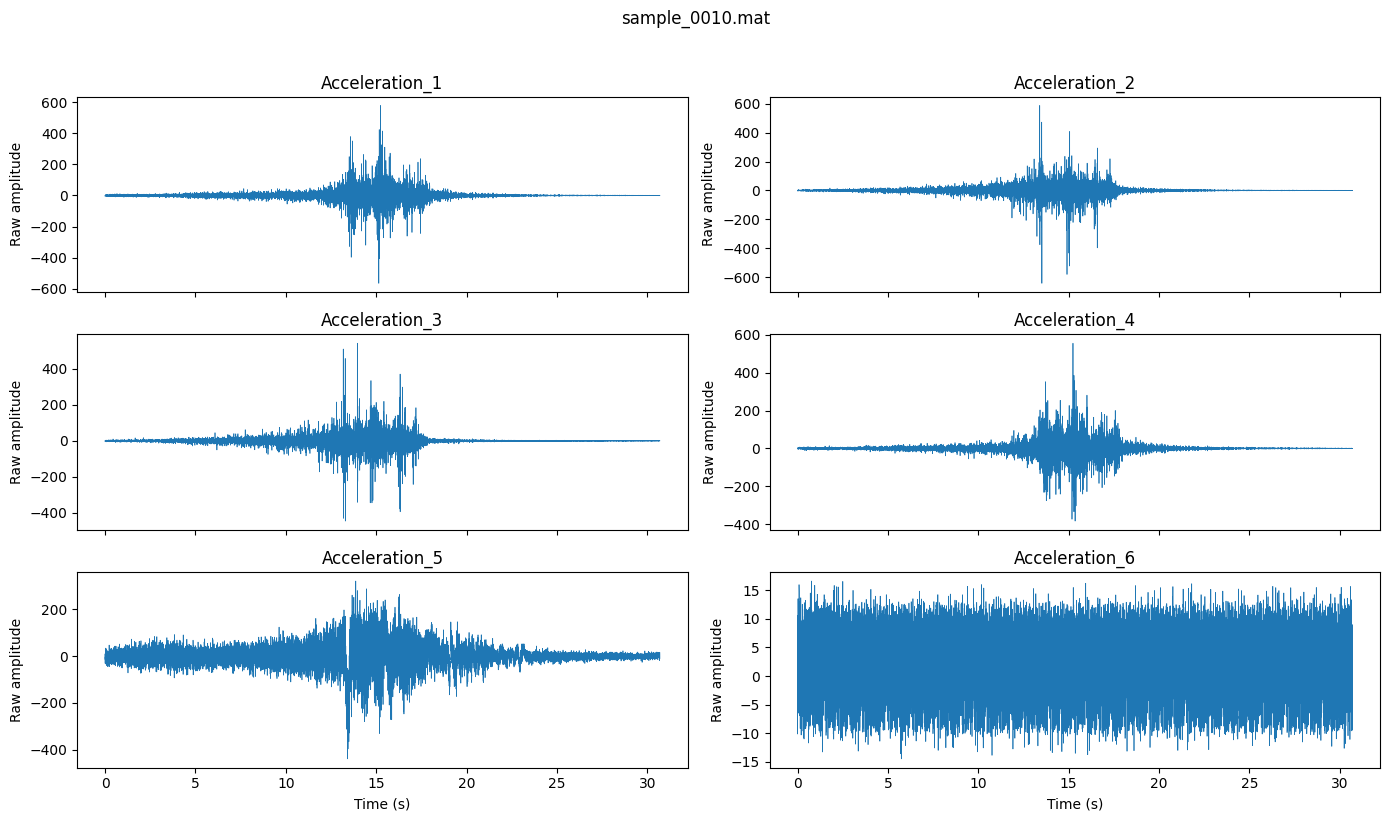

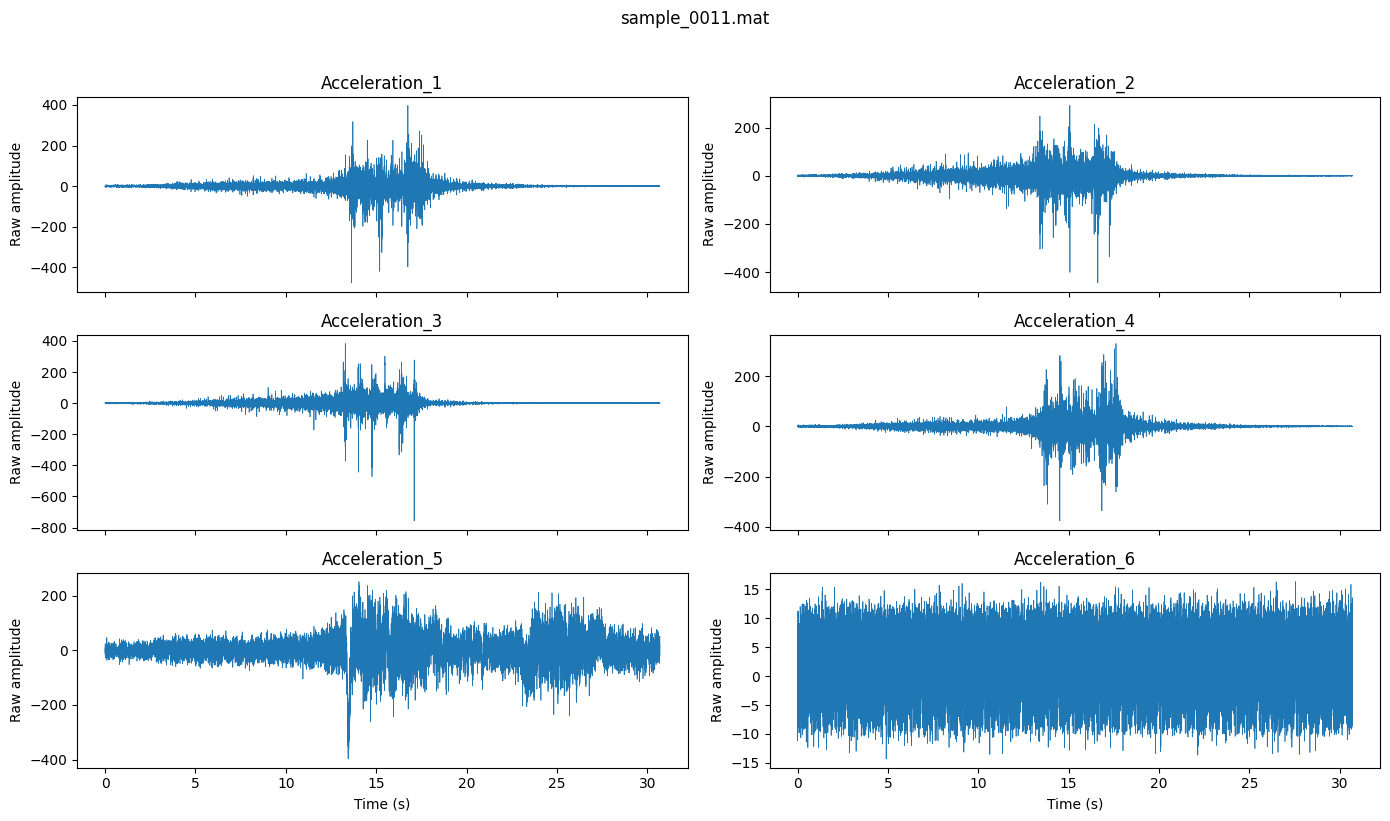

In [2]:
channels = [f'Acceleration_{i}' for i in range(1, 7)]
rate = 10_000.0  # Fixed accelerometer sampling rate used in the study

for path in paths:
    data = loadmat(path)
    fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex=True)
    fig.suptitle(path.name, y=1.02)

    for channel, axis in zip(channels, axes.flat):
        values = np.ravel(data[channel])
        stride = max(1, len(values) // 20000)
        indices = np.arange(0, len(values), stride)
        axis.plot(indices / rate, values[indices], linewidth=0.5)
        axis.set_title(channel)
        axis.set_ylabel('Raw amplitude')

    for axis in axes[-1]:
        axis.set_xlabel('Time (s)')

    fig.tight_layout()
    plt.show()